Mild_Dementia: 10000 files
Moderate_Dementia: 8000 files
Non_Demented: 40000 files
Very_mild_Dementia: 20000 files
Epoch 1/10 | Loss=1555.7483 | Acc=0.6574
Epoch 2/10 | Loss=1264.0584 | Acc=0.7223
Epoch 3/10 | Loss=1156.1391 | Acc=0.7497
Epoch 4/10 | Loss=1092.4341 | Acc=0.7633
Epoch 5/10 | Loss=1040.7447 | Acc=0.7734
Epoch 6/10 | Loss=995.7423 | Acc=0.7861
Epoch 7/10 | Loss=967.1868 | Acc=0.7898
Epoch 8/10 | Loss=940.1742 | Acc=0.7976
Epoch 9/10 | Loss=910.2352 | Acc=0.8055
Epoch 10/10 | Loss=881.1045 | Acc=0.8116

Test Accuracy: 81.33%

Classification Report:
                    precision    recall  f1-score   support

     Mild_Dementia       0.70      0.53      0.60      2000
 Moderate_Dementia       0.76      0.85      0.80      1600
      Non_Demented       0.89      0.93      0.91      8000
Very_mild_Dementia       0.72      0.70      0.71      4000

          accuracy                           0.81     15600
         macro avg       0.77      0.75      0.76     15600
      weig

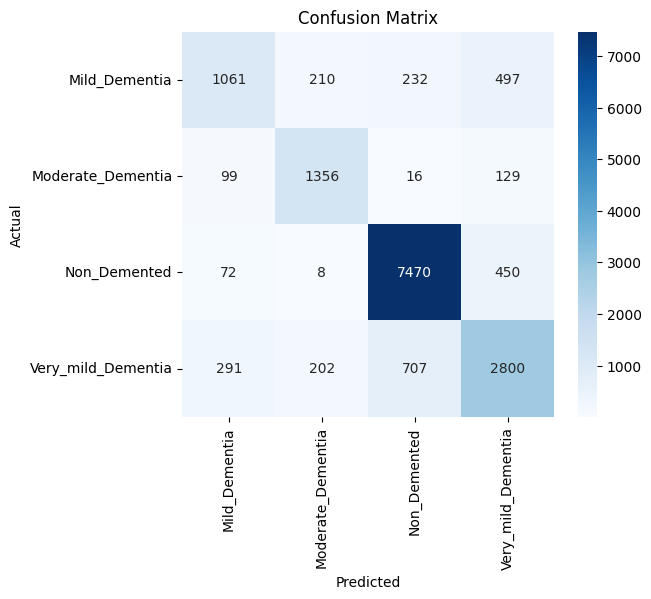

In [11]:
import os
import glob
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

dataset_dir = "C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Processed_Final"

# EXACT FOLDER NAMES FROM YOUR SCREENSHOT
classes = [
    "Mild_Dementia",
    "Moderate_Dementia",
    "Non_Demented",
    "Very_mild_Dementia"
]

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# LOAD IMAGES
# -------------------------------

image_paths = []
labels = []

for class_idx, class_name in enumerate(classes):
    class_path = os.path.join(dataset_dir, class_name)
    files = glob.glob(class_path + "/*.*")   # accept .jpg/.png/.jpeg etc.
    print(f"{class_name}: {len(files)} files")

    for img in files:
        image_paths.append(img)
        labels.append(class_idx)

if len(image_paths) == 0:
    raise ValueError("No images found. Check folder structure again.")

# -------------------------------
# TRAIN / TEST SPLIT
# -------------------------------

train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths, labels, test_size=0.2, random_state=42, stratify=labels
)

# -------------------------------
# DATASET CLASS
# -------------------------------

class MRIDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

# -------------------------------
# TRANSFORMS
# -------------------------------

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

train_dataset = MRIDataset(train_paths, train_labels, transform)
test_dataset = MRIDataset(test_paths, test_labels, transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# -------------------------------
# RESNET50 MODEL
# -------------------------------

model = models.resnet50(weights="IMAGENET1K_V2")

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Sequential(
    nn.Linear(model.fc.in_features, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 4)
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-4)

# -------------------------------
# TRAIN LOOP
# -------------------------------

for epoch in range(EPOCHS):
    model.train()
    total_loss, total_correct, total_samples = 0, 0, 0

    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)

        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, lbls)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, pred = out.max(1)
        total_correct += pred.eq(lbls).sum().item()
        total_samples += lbls.size(0)

    acc = total_correct / total_samples
    print(f"Epoch {epoch+1}/{EPOCHS} | Loss={total_loss:.4f} | Acc={acc:.4f}")

# -------------------------------
# EVALUATION
# -------------------------------

model.eval()
all_preds, all_true = [], []
correct, total = 0, 0

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        out = model(imgs)
        _, pred = out.max(1)

        all_preds.extend(pred.cpu().numpy())
        all_true.extend(lbls.cpu().numpy())

        correct += pred.eq(lbls).sum().item()
        total += lbls.size(0)

print(f"\nTest Accuracy: {correct/total*100:.2f}%")

print("\nClassification Report:")
print(classification_report(all_true, all_preds, target_names=classes))

cm = confusion_matrix(all_true, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()
